In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Load MNIST
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

# Preserve original dataset split
X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (60000, 784)
Testing: (10000, 784)


In [3]:

# Baseline: 1NN using the original training dataset

baseline_knn = KNeighborsClassifier(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=1
)

start = time.time()

baseline_knn.fit(X_train, y_train)

baseline_train_time = time.time() - start

start = time.time()

baseline_predictions = baseline_knn.predict(X_test)

baseline_prediction_time = time.time() - start

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Original training samples:", len(X_train))
print(f"1NN accuracy: {baseline_accuracy * 100:.2f}%")
print(f"Training time: {baseline_train_time:.2f}s")
print(f"Prediction time: {baseline_prediction_time:.2f}s")

Original training samples: 60000
1NN accuracy: 96.91%
Training time: 0.10s
Prediction time: 4.26s


In [5]:

# Custom Edited Nearest Neighbour (ENN)
# One-pass, three-neighbour editing

def edited_nearest_neighbour(X, y, k=3):

    if k % 2 == 0:
        raise ValueError("Use an odd value of k.")

    if len(X) <= k:
        raise ValueError("Dataset is too small.")

    # Find k+1 neighbours, including the sample itself
    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric="euclidean",
        algorithm="brute",
        n_jobs=1
    )

    nn.fit(X)

    # Use the sample's own index as a query
    # and remove it explicitly from neighbours.
    distances, indices = nn.kneighbors(
        X,
        n_neighbors=k + 1
    )

    # Remove the sample itself from each row
    selected_indices = []

    for i in range(len(X)):
        neighbours = indices[i]
        neighbours = neighbours[neighbours != i][:k]

        if len(neighbours) != k:
            raise RuntimeError(
                "Not enough non-self neighbours."
            )

        neighbour_labels = y[neighbours]

        # Majority voting
        votes = np.bincount(
            neighbour_labels,
            minlength=10
        )

        predicted_label = np.argmax(votes)

        # Keep correctly classified examples
        if predicted_label == y[i]:
            selected_indices.append(i)

    selected_indices = np.array(selected_indices)

    return X[selected_indices], y[selected_indices]

In [6]:

# Apply data reduction to the MNIST training set

start = time.time()

X_reduced, y_reduced = edited_nearest_neighbour(
    X_train,
    y_train,
    k=3
)

reduction_time = time.time() - start

original_size = len(X_train)
reduced_size = len(X_reduced)

reduction_percentage = (
    (original_size - reduced_size)
    / original_size
) * 100

print("Original samples:", original_size)
print("Remaining samples:", reduced_size)
print(f"Reduction: {reduction_percentage:.2f}%")
print(f"Reduction time: {reduction_time:.2f}s")


Original samples: 60000
Remaining samples: 58438
Reduction: 2.60%
Reduction time: 22.05s


In [7]:

# Evaluate 1NN after ENN reduction

reduced_knn = KNeighborsClassifier(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=1
)

start = time.time()

reduced_knn.fit(X_reduced, y_reduced)

reduced_train_time = time.time() - start

start = time.time()

reduced_predictions = reduced_knn.predict(X_test)

reduced_prediction_time = time.time() - start

reduced_accuracy = accuracy_score(
    y_test,
    reduced_predictions
)

print(f"Original 1NN accuracy: {baseline_accuracy * 100:.2f}%")
print(f"Reduced 1NN accuracy: {reduced_accuracy * 100:.2f}%")
print(f"Dataset reduction: {reduction_percentage:.2f}%")
print(f"Reduced prediction time: {reduced_prediction_time:.2f}s")

Original 1NN accuracy: 96.91%
Reduced 1NN accuracy: 96.90%
Dataset reduction: 2.60%
Reduced prediction time: 4.07s


In [8]:

comparison = pd.DataFrame({
    "Dataset": ["Original", "ENN Reduced"],
    "Training Samples": [
        len(X_train),
        len(X_reduced)
    ],
    "Accuracy (%)": [
        baseline_accuracy * 100,
        reduced_accuracy * 100
    ],
    "Prediction Time (s)": [
        baseline_prediction_time,
        reduced_prediction_time
    ]
})

print(comparison.to_string(index=False))

    Dataset  Training Samples  Accuracy (%)  Prediction Time (s)
   Original             60000         96.91             4.259979
ENN Reduced             58438         96.90             4.067831


/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklear

Original PCA shape: (60000, 2)
Explained variance: [0.09704718 0.0709596 ]
Total explained variance: 0.16800678


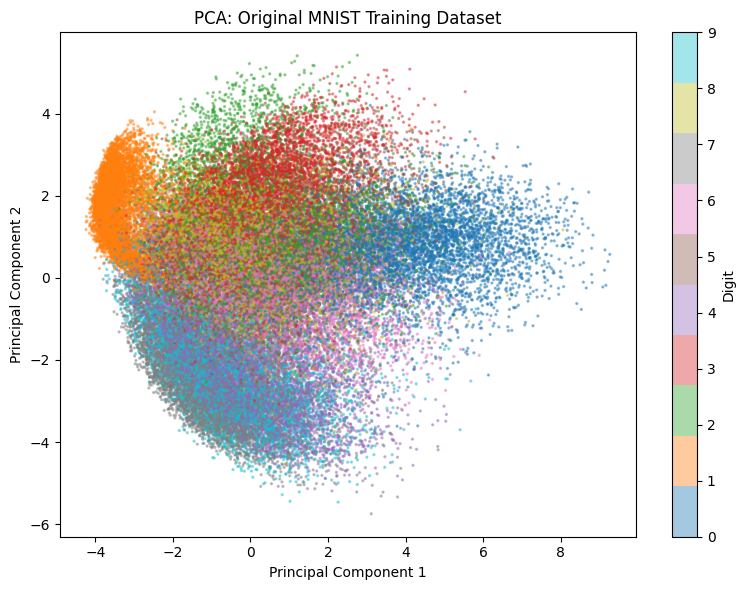

In [9]:

# Step 7: PCA on the original MNIST training set

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

pca_original = PCA(
    n_components=2,
    random_state=42
)

X_original_pca = pca_original.fit_transform(X_train)

print("Original PCA shape:", X_original_pca.shape)

print(
    "Explained variance:",
    pca_original.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca_original.explained_variance_ratio_.sum()
)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_original_pca[:, 0],
    X_original_pca[:, 1],
    c=y_train,
    cmap="tab10",
    s=2,
    alpha=0.4
)

plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Original MNIST Training Dataset")

plt.tight_layout()
plt.savefig("pca_original.png", dpi=300)
plt.show()

/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklear

Reduced PCA shape: (58438, 2)
Explained variance: [0.0975324  0.07150637]
Total explained variance: 0.16903877


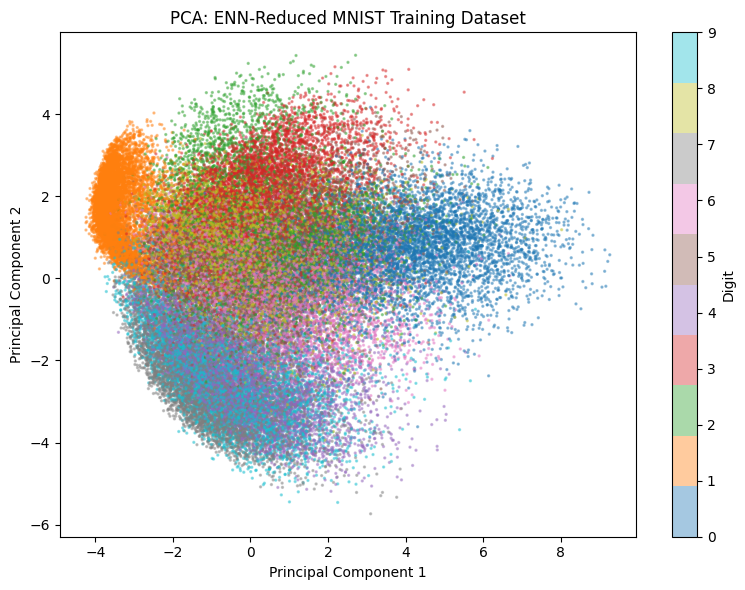

In [10]:

# Step 8: PCA on the reduced MNIST dataset

pca_reduced = PCA(
    n_components=2,
    random_state=42
)

X_reduced_pca = pca_reduced.fit_transform(X_reduced)

print("Reduced PCA shape:", X_reduced_pca.shape)

print(
    "Explained variance:",
    pca_reduced.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca_reduced.explained_variance_ratio_.sum()
)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_reduced_pca[:, 0],
    X_reduced_pca[:, 1],
    c=y_reduced,
    cmap="tab10",
    s=2,
    alpha=0.4
)

plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: ENN-Reduced MNIST Training Dataset")

plt.tight_layout()
plt.savefig("pca_reduced.png", dpi=300)
plt.show()

In [11]:

# Step 9: Compare PCA explained variance

pca_comparison = pd.DataFrame({
    "Dataset": ["Original", "ENN Reduced"],
    "PC1 (%)": [
        pca_original.explained_variance_ratio_[0] * 100,
        pca_reduced.explained_variance_ratio_[0] * 100
    ],
    "PC2 (%)": [
        pca_original.explained_variance_ratio_[1] * 100,
        pca_reduced.explained_variance_ratio_[1] * 100
    ],
    "Total Variance (%)": [
        pca_original.explained_variance_ratio_.sum() * 100,
        pca_reduced.explained_variance_ratio_.sum() * 100
    ]
})

print(pca_comparison.to_string(index=False))

    Dataset  PC1 (%)  PC2 (%)  Total Variance (%)
   Original 9.704718 7.095960           16.800678
ENN Reduced 9.753240 7.150637           16.903877


/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklear

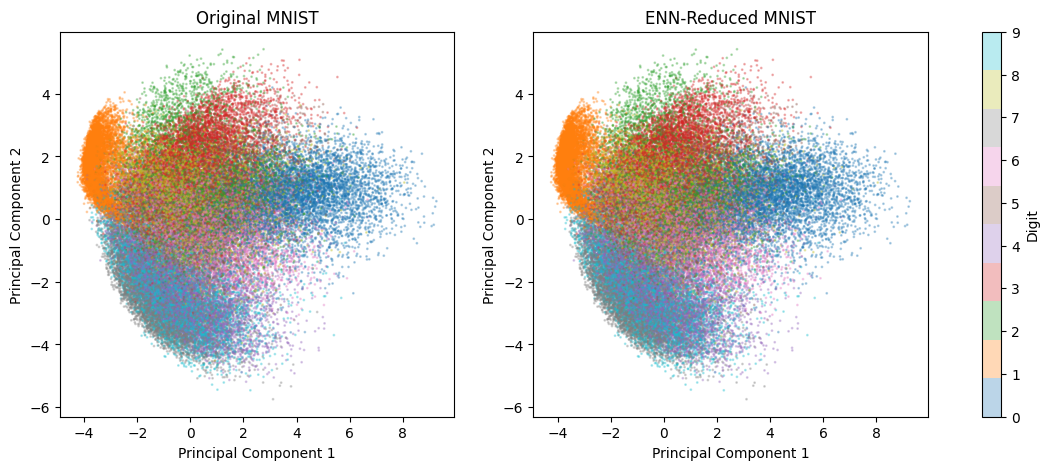

In [12]:

# Fit PCA only on the original training data
shared_pca = PCA(n_components=2, random_state=42)
X_original_shared = shared_pca.fit_transform(X_train)

# Project the reduced data into the SAME PCA space
X_reduced_shared = shared_pca.transform(X_reduced)

# Plot using identical axes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, labels, title in [
    (axes[0], X_original_shared, y_train, "Original MNIST"),
    (axes[1], X_reduced_shared, y_reduced, "ENN-Reduced MNIST")
]:
    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=labels,
        cmap="tab10",
        s=1,
        alpha=0.3,
        vmin=0,
        vmax=9
    )
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

# Match the axes for fair comparison
axes[1].set_xlim(axes[0].get_xlim())
axes[1].set_ylim(axes[0].get_ylim())

fig.colorbar(scatter, ax=axes, label="Digit", ticks=range(10))

plt.savefig("pca_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:

# Step 10: Custom Condensed Nearest Neighbour (CNN)

import numpy as np
from sklearn.neighbors import KNeighborsClassifier
import time

def condensed_nearest_neighbour(
    X, y, random_state=42, max_passes=10
):
    rng = np.random.default_rng(random_state)

    # Initialise with one example per class
    selected = []

    for label in np.unique(y):
        candidates = np.flatnonzero(y == label)
        selected.append(int(rng.choice(candidates)))

    selected_set = set(selected)
    order = rng.permutation(len(y))

    for pass_number in range(max_passes):

        additions = 0

        # Build the model at the start of the pass
        model = KNeighborsClassifier(
            n_neighbors=1,
            algorithm="brute",
            metric="euclidean",
            n_jobs=1
        )

        model.fit(X[selected], y[selected])

        for i in order:

            i = int(i)

            if i in selected_set:
                continue

            prediction = model.predict(X[i:i+1])[0]

            if prediction != y[i]:
                selected.append(i)
                selected_set.add(i)
                additions += 1

                # Update the reference set
                model.fit(X[selected], y[selected])

        print(
            f"Pass {pass_number + 1}: "
            f"added {additions} samples, "
            f"total {len(selected)}"
        )

        if additions == 0:
            break

    return X[selected], y[selected]

In [14]:

# Step 11: Test CNN on a small subset first

from sklearn.model_selection import train_test_split

X_small, _, y_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=2000,
    stratify=y_train,
    random_state=42
)

start = time.time()

X_cnn_small, y_cnn_small = condensed_nearest_neighbour(
    X_small,
    y_small,
    max_passes=5
)

elapsed = time.time() - start

print("Original subset:", len(X_small))
print("Condensed subset:", len(X_cnn_small))
print(
    "Reduction:",
    f"{100 * (1 - len(X_cnn_small)/len(X_small)):.2f}%"
)
print(f"Time: {elapsed:.2f}s")


Pass 1: added 404 samples, total 414
Pass 2: added 88 samples, total 502
Pass 3: added 13 samples, total 515
Pass 4: added 1 samples, total 516
Pass 5: added 0 samples, total 516
Original subset: 2000
Condensed subset: 516
Reduction: 74.20%
Time: 8.57s


In [15]:

# Step 12: Evaluate the condensed subset

cnn_model = KNeighborsClassifier(
    n_neighbors=1,
    algorithm="brute",
    metric="euclidean",
    n_jobs=1
)

cnn_model.fit(X_cnn_small, y_cnn_small)

cnn_predictions = cnn_model.predict(X_test)

cnn_accuracy = accuracy_score(y_test, cnn_predictions)

print(f"CNN subset size: {len(X_cnn_small)}")
print(f"CNN test accuracy: {cnn_accuracy * 100:.2f}%")


CNN subset size: 516
CNN test accuracy: 86.34%


In [16]:

# Step 13: Fair comparison on the same 2,000 examples

import pandas as pd
import time

def evaluate_1nn(X_reference, y_reference):
    model = KNeighborsClassifier(
        n_neighbors=1,
        metric="euclidean",
        algorithm="brute",
        n_jobs=1
    )

    model.fit(X_reference, y_reference)

    start = time.perf_counter()
    predictions = model.predict(X_test)
    prediction_time = time.perf_counter() - start

    accuracy = accuracy_score(y_test, predictions)

    return accuracy, prediction_time

# Apply ENN to the same 2,000 examples
X_enn_small, y_enn_small = edited_nearest_neighbour(
    X_small,
    y_small,
    k=3
)

# Evaluate original, ENN and CNN
datasets = [
    ("Original", X_small, y_small),
    ("ENN", X_enn_small, y_enn_small),
    ("CNN", X_cnn_small, y_cnn_small)
]

rows = []

for name, X_ref, y_ref in datasets:

    acc, pred_time = evaluate_1nn(X_ref, y_ref)

    rows.append({
        "Method": name,
        "Samples": len(X_ref),
        "Reduction (%)": (
            100 * (1 - len(X_ref) / len(X_small))
        ),
        "Accuracy (%)": acc * 100,
        "Prediction Time (s)": pred_time
    })

comparison_small = pd.DataFrame(rows)

print(comparison_small.to_string(index=False))

  Method  Samples  Reduction (%)  Accuracy (%)  Prediction Time (s)
Original     2000           0.00         91.20             0.339816
     ENN     1801           9.95         90.05             0.298948
     CNN      516          74.20         86.34             0.141753


/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/

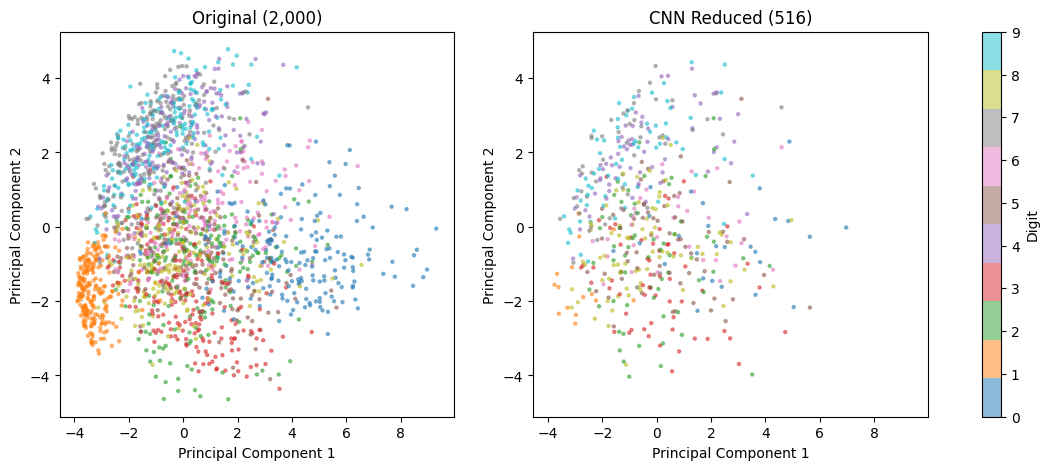

In [17]:

# Step 14: PCA before and after CNN reduction

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_small = PCA(
    n_components=2,
    random_state=42
)

X_small_pca = pca_small.fit_transform(X_small)
X_cnn_pca = pca_small.transform(X_cnn_small)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, labels, title in [
    (axes[0], X_small_pca, y_small, "Original (2,000)"),
    (axes[1], X_cnn_pca, y_cnn_small, "CNN Reduced (516)")
]:
    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=labels,
        cmap="tab10",
        s=5,
        alpha=0.5,
        vmin=0,
        vmax=9
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

axes[1].set_xlim(axes[0].get_xlim())
axes[1].set_ylim(axes[0].get_ylim())

fig.colorbar(scatter, ax=axes, ticks=range(10), label="Digit")

plt.savefig(
    "pca_cnn_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

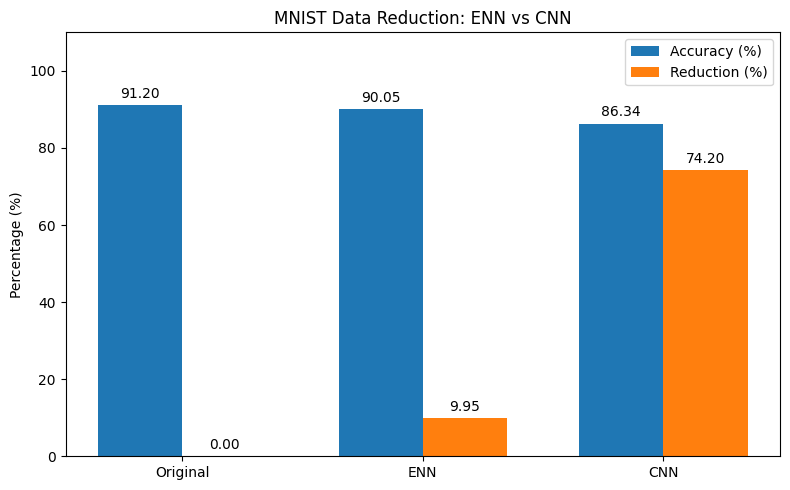

In [18]:

# Step 15: Compare accuracy and dataset reduction

import matplotlib.pyplot as plt
import numpy as np

methods = ["Original", "ENN", "CNN"]
accuracy = [91.20, 90.05, 86.34]
reduction = [0.00, 9.95, 74.20]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2,
    accuracy,
    width,
    label="Accuracy (%)"
)

bars2 = ax.bar(
    x + width / 2,
    reduction,
    width,
    label="Reduction (%)"
)

ax.set_ylabel("Percentage (%)")
ax.set_title("MNIST Data Reduction: ENN vs CNN")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 110)
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("data_reduction_comparison.png", dpi=300)
plt.show()

In [19]:

# Step 16: Lecture-based two-subset cleaning

import numpy as np
from sklearn.neighbors import KNeighborsClassifier

def lecture_cleaning(X, y, random_state=42, max_passes=30):
    rng = np.random.default_rng(random_state)

    # Randomly divide S into S1 and S2
    indices = rng.permutation(len(X))
    midpoint = len(indices) // 2

    S1 = indices[:midpoint]
    S2 = indices[midpoint:]

    history = []

    for pass_num in range(max_passes):

        before = len(S1) + len(S2)

        # Classify S1 using S2 with 1NN
        model = KNeighborsClassifier(
            n_neighbors=1,
            metric="euclidean",
            algorithm="brute",
            n_jobs=1
        )

        model.fit(X[S2], y[S2])
        pred_S1 = model.predict(X[S1])

        # Remove misclassified instances from S1
        S1 = S1[pred_S1 == y[S1]]

        if len(S1) == 0:
            raise RuntimeError(
                "S1 became empty during cleaning."
            )

        # Classify S2 using the updated S1
        model.fit(X[S1], y[S1])
        pred_S2 = model.predict(X[S2])

        # Remove misclassified instances from S2
        S2 = S2[pred_S2 == y[S2]]

        if len(S2) == 0:
            raise RuntimeError(
                "S2 became empty during cleaning."
            )

        after = len(S1) + len(S2)
        removed = before - after

        history.append({
            "Pass": pass_num + 1,
            "S1": len(S1),
            "S2": len(S2),
            "Remaining": after,
            "Removed": removed
        })

        print(
            f"Pass {pass_num + 1}: "
            f"removed {removed}, "
            f"remaining {after}"
        )

        # Stabilisation: neither subset changes
        if removed == 0:
            print("Cleaning converged.")
            break

    # Return the union of S1 and S2
    cleaned_indices = np.concatenate([S1, S2])

    return (
        X[cleaned_indices],
        y[cleaned_indices],
        history
    )


In [20]:

# Step 17: Clean the original 2,000-example subset

import time

start = time.perf_counter()

X_cleaned, y_cleaned, cleaning_history = lecture_cleaning(
    X_small,
    y_small,
    random_state=42
)

cleaning_time = time.perf_counter() - start

print("\nOriginal samples:", len(X_small))
print("Cleaned samples:", len(X_cleaned))

print(
    "Reduction: "
    f"{100 * (1 - len(X_cleaned)/len(X_small)):.2f}%"
)

print(f"Cleaning time: {cleaning_time:.2f}s")


Pass 1: removed 238, remaining 1762
Pass 2: removed 7, remaining 1755
Pass 3: removed 0, remaining 1755
Cleaning converged.

Original samples: 2000
Cleaned samples: 1755
Reduction: 12.25%
Cleaning time: 0.19s


In [21]:

# Step 18: CNN after preliminary cleaning

print("Remaining classes:", np.unique(y_cleaned))

if len(np.unique(y_cleaned)) != 10:
    raise ValueError(
        "Cleaning removed at least one entire digit class."
    )

start = time.perf_counter()

X_cleaned_cnn, y_cleaned_cnn = condensed_nearest_neighbour(
    X_cleaned,
    y_cleaned,
    random_state=42,
    max_passes=10
)

cnn_after_cleaning_time = time.perf_counter() - start

print("\nOriginal:", len(X_small))
print("After cleaning:", len(X_cleaned))
print("After cleaning + CNN:", len(X_cleaned_cnn))

print(
    "Total reduction: "
    f"{100 * (1 - len(X_cleaned_cnn)/len(X_small)):.2f}%"
)

print(
    f"CNN time: {cnn_after_cleaning_time:.2f}s"
)


Remaining classes: [0 1 2 3 4 5 6 7 8 9]
Pass 1: added 268 samples, total 278
Pass 2: added 37 samples, total 315
Pass 3: added 6 samples, total 321
Pass 4: added 0 samples, total 321

Original: 2000
After cleaning: 1755
After cleaning + CNN: 321
Total reduction: 83.95%
CNN time: 6.53s


In [22]:

# Step 19: Final lecture-based comparison

datasets_final = [
    ("Original", X_small, y_small),
    ("Cleaning", X_cleaned, y_cleaned),
    ("CNN", X_cnn_small, y_cnn_small),
    ("Cleaning + CNN", X_cleaned_cnn, y_cleaned_cnn)
]

rows = []

for name, X_ref, y_ref in datasets_final:

    accuracy, prediction_time = evaluate_1nn(
        X_ref,
        y_ref
    )

    rows.append({
        "Method": name,
        "Samples": len(X_ref),
        "Reduction (%)": 100 * (
            1 - len(X_ref) / len(X_small)
        ),
        "Accuracy (%)": accuracy * 100,
        "Prediction Time (s)": prediction_time
    })

lecture_comparison = pd.DataFrame(rows)

print(lecture_comparison.to_string(index=False))

lecture_comparison.to_csv(
    "lecture_reduction_results.csv",
    index=False
)


        Method  Samples  Reduction (%)  Accuracy (%)  Prediction Time (s)
      Original     2000           0.00         91.20             0.284488
      Cleaning     1755          12.25         89.90             0.239192
           CNN      516          74.20         86.34             0.167231
Cleaning + CNN      321          83.95         85.14             0.124227


/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/

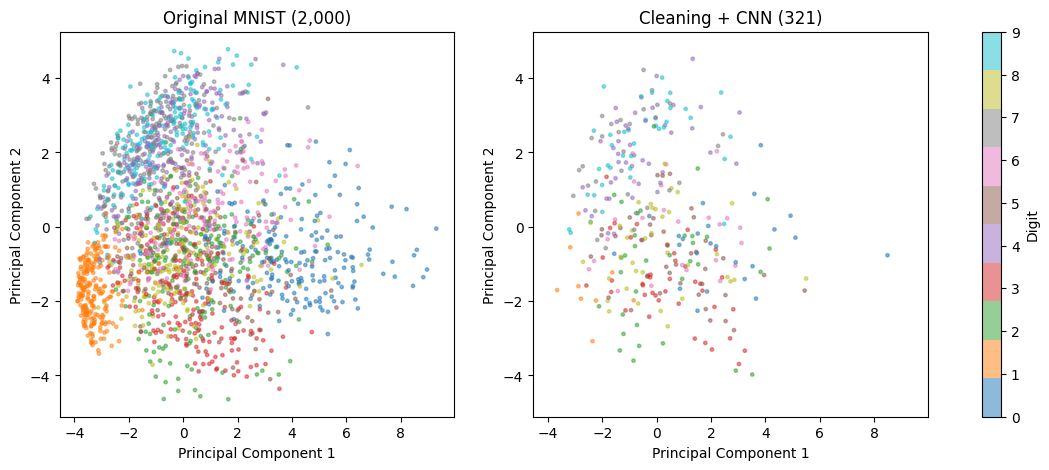

In [23]:

# Step 20: PCA comparison for lecture-based reduction

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Fit PCA on original 2,000-example dataset
pca_final = PCA(
    n_components=2,
    random_state=42
)

X_original_pca_final = pca_final.fit_transform(X_small)

# Use same PCA projection for reduced data
X_final_pca = pca_final.transform(X_cleaned_cnn)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, labels, title in [
    (axes[0], X_original_pca_final, y_small,
     "Original MNIST (2,000)"),
    (axes[1], X_final_pca, y_cleaned_cnn,
     "Cleaning + CNN (321)")
]:
    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=labels,
        cmap="tab10",
        s=6,
        alpha=0.5,
        vmin=0,
        vmax=9
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

axes[1].set_xlim(axes[0].get_xlim())
axes[1].set_ylim(axes[0].get_ylim())

fig.colorbar(
    scatter,
    ax=axes,
    ticks=range(10),
    label="Digit"
)

plt.savefig(
    "pca_cleaning_cnn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Final Experiment 2 comparison graph

import numpy as np
import matplotlib.pyplot as plt

methods = [
    "Original",
    "Cleaning",
    "CNN",
    "Cleaning + CNN"
]

accuracy = [91.20, 89.90, 86.34, 85.14]
reduction = [0.00, 12.25, 74.20, 83.95]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    accuracy,
    width,
    label="Test accuracy (%)"
)

bars2 = ax.bar(
    x + width / 2,
    reduction,
    width,
    label="Training-set reduction (%)"
)

ax.set_ylabel("Percentage (%)")
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=10)
ax.set_ylim(0, 110)
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()

plt.savefig(
    "experiment2_final_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
